In [ ]:
from google.colab import drive


In [ ]:
import pandas as pd
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Mašinsko učenje/clean_dataset.csv')

Mounted at /content/drive


In [ ]:
df.head()

,Attrition_Flag_clean,Customer_Age_clean,Gender_clean,Dependent_count_clean,Education_Level_clean,Marital_Status_clean,Income_Category_clean,Card_Category_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
0,Existing Customer,45.0,M,3.0,High School,Married,$60K - $80K,Blue,39.0,4.0,1.0,3.0,4537.0,777.0,3473.0,0.737,1144.0,42.0,1.625,0.061
1,Existing Customer,49.0,F,5.0,Graduate,Single,Less than $40K,Blue,44.0,6.0,1.0,2.0,8256.0,1249.0,3473.0,0.737,1291.0,67.0,3.714,0.105
2,Existing Customer,46.0,M,3.0,Graduate,Married,$80K - $120K,Blue,36.0,4.0,1.0,2.0,3418.0,0.0,3418.0,2.594,1887.0,20.0,2.333,0.000
3,Existing Customer,46.0,F,4.0,High School,Unknown,Less than $40K,Blue,34.0,3.0,4.0,2.0,3313.0,1249.0,796.0,1.405,1171.0,20.0,2.333,0.760
4,Existing Customer,46.0,M,3.0,Uneducated,Married,$60K - $80K,Blue,36.0,5.0,2.0,2.0,4716.0,0.0,4716.0,2.175,3899.0,28.0,2.500,0.000


# a)

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Attrition_Flag_clean            10127 non-null  object 
 1   Customer_Age_clean              10127 non-null  float64
 2   Gender_clean                    10127 non-null  object 
 3   Dependent_count_clean           10127 non-null  float64
 4   Education_Level_clean           10127 non-null  object 
 5   Marital_Status_clean            10127 non-null  object 
 6   Income_Category_clean           10127 non-null  object 
 7   Card_Category_clean             10127 non-null  object 
 8   Months_on_book_clean            10127 non-null  float64
 9   Total_Relationship_Count_clean  10127 non-null  float64
 10  Months_Inactive_clean           10127 non-null  float64
 11  Contacts_Count_clean            10127 non-null  float64
 12  Credit_Limit_clean              

In [ ]:
X = df.drop(columns=['Attrition_Flag_clean'])


In [ ]:
X.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Customer_Age_clean              10127 non-null  float64
 1   Gender_clean                    10127 non-null  object 
 2   Dependent_count_clean           10127 non-null  float64
 3   Education_Level_clean           10127 non-null  object 
 4   Marital_Status_clean            10127 non-null  object 
 5   Income_Category_clean           10127 non-null  object 
 6   Card_Category_clean             10127 non-null  object 
 7   Months_on_book_clean            10127 non-null  float64
 8   Total_Relationship_Count_clean  10127 non-null  float64
 9   Months_Inactive_clean           10127 non-null  float64
 10  Contacts_Count_clean            10127 non-null  float64
 11  Credit_Limit_clean              10127 non-null  float64
 12  Total_Revolving_Bal_clean       

In [ ]:
num_cols = X.select_dtypes(include=['float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

num_cols, cat_cols


(Index(['Customer_Age_clean', 'Dependent_count_clean', 'Months_on_book_clean',
        'Total_Relationship_Count_clean', 'Months_Inactive_clean',
        'Contacts_Count_clean', 'Credit_Limit_clean',
        'Total_Revolving_Bal_clean', 'Avg_Open_To_Buy_clean',
        'Total_Amt_Chng_clean', 'Total_Trans_Amt_clean', 'Total_Trans_Ct_clean',
        'Total_Ct_Chng_clean', 'Avg_Utilization_Ratio_clean'],
       dtype='object'),
 Index(['Gender_clean', 'Education_Level_clean', 'Marital_Status_clean',
        'Income_Category_clean', 'Card_Category_clean'],
       dtype='object'))

# One-hot encoding za kategoričke varijable

In [ ]:
X_cat = pd.get_dummies(X[cat_cols], drop_first=True)


In [ ]:
X_num = X[num_cols]

X_prepared = pd.concat([X_num, X_cat], axis=1)


# Skaliranje podataka

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_prepared)

X_scaled = pd.DataFrame(X_scaled, columns=X_prepared.columns)


In [ ]:
X_scaled.describe()


,Customer_Age_clean,Dependent_count_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,...,Marital_Status_clean_Unknown,Income_Category_clean_$40K - $60K,Income_Category_clean_$60K - $80K,Income_Category_clean_$80K - $120K,Income_Category_clean_Less than $40K,Income_Category_clean_Unknown,Card_Category_clean_Gold,Card_Category_clean_Platinum,Card_Category_clean_Silver,Card_Category_clean_Unknown
count,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,...,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,10127.000000,10127.000000,1.012700e+04,1.012700e+04
mean,1.627786e-16,-1.234872e-16,-4.111564e-16,-1.796178e-16,2.090863e-16,8.419584e-18,-1.010350e-16,-1.080513e-16,-1.122611e-17,4.462380e-16,...,-8.279258e-17,3.508160e-19,1.824243e-17,7.016320e-17,-1.122611e-17,-7.437299e-17,0.000000,0.000000,-2.245222e-17,3.902828e-17
std,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,...,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049,1.000049,1.000049e+00,1.000049e+00
min,-2.872942e+00,-1.923042e+00,-3.268407e+00,-2.076320e+00,-2.516008e+00,-2.328674e+00,-7.649898e-01,-1.562393e+00,-8.016640e-01,-3.845350e+00,...,-3.375779e-01,-4.550079e-01,-3.933599e-01,-4.168173e-01,-7.169227e-01,-3.990316e-01,-0.106227,-0.043355,-2.368670e-01,-1.756213e-01
25%,-4.615274e-01,-2.154886e-01,-2.766181e-01,-6.237352e-01,-3.009673e-01,-3.483673e-01,-5.843559e-01,-5.824233e-01,-6.076779e-01,-4.584751e-01,...,-3.375779e-01,-4.550079e-01,-3.933599e-01,-4.168173e-01,-7.169227e-01,-3.990316e-01,-0.106227,-0.043355,-2.368670e-01,-1.756213e-01
50%,-3.598373e-02,-2.154886e-01,8.314159e-03,1.025574e-01,-3.009673e-01,-3.483673e-01,-3.845314e-01,1.258585e-01,-3.795629e-01,-9.177589e-02,...,-3.375779e-01,-4.550079e-01,-3.933599e-01,-4.168173e-01,-7.169227e-01,-3.990316e-01,-0.106227,-0.043355,-2.368670e-01,-1.756213e-01
75%,5.314079e-01,6.382880e-01,2.932464e-01,8.288499e-01,8.065530e-01,6.417858e-01,7.773535e-02,6.509874e-01,8.129892e-02,3.258538e-01,...,-3.375779e-01,-4.550079e-01,-3.933599e-01,-4.168173e-01,1.394850e+00,-3.990316e-01,-0.106227,-0.043355,-2.368670e-01,-1.756213e-01
max,3.084670e+00,2.345841e+00,2.857637e+00,1.555142e+00,4.129114e+00,3.612245e+00,3.296291e+00,1.839793e+00,3.404233e+00,1.345572e+01,...,2.962279e+00,2.197764e+00,2.542201e+00,2.399133e+00,1.394850e+00,2.506067e+00,9.413791,23.065125,4.221779e+00,5.694071e+00


In [ ]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

def hopkins_statistic(X, n_samples=100):
    X = np.array(X)
    n, d = X.shape

    sample_indices = np.random.choice(n, n_samples, replace=False)
    X_sample = X[sample_indices]

    nbrs = NearestNeighbors(n_neighbors=2).fit(X)

    u_distances = []
    w_distances = []

    for x in X_sample:
        random_point = np.random.uniform(
            np.min(X, axis=0),
            np.max(X, axis=0)
        )

        u_distances.append(
            nbrs.kneighbors([random_point], return_distance=True)[0][0][1]
        )
        w_distances.append(
            nbrs.kneighbors([x], return_distance=True)[0][0][1]
        )

    H = sum(u_distances) / (sum(u_distances) + sum(w_distances))
    return H


In [ ]:
hopkins_value = hopkins_statistic(X_scaled)
hopkins_value


np.float64(0.8376095375139384)

# b)

S obzirom na prirodu podataka, mogu se postaviti sljedeći zadaci i hipoteze za klastering:

1. Segmentacija korisnika prema obrazovanju

    * Hipoteza: Nivo obrazovanja (`Education_Level_clean`) može razlikovati korisnike i potencijalno poslužiti za formiranje klastera.
    * Cilj: Istražiti da li postoje grupe korisnika s različitim obrazovnim profilima i kako to može utjecati na obrasce korištenja kartica i prihode.

---

2. Segmentacija prema finansijskim i transakcijskim pokazateljima

    * Hipoteza: Razlike u finansijskim i transakcijskim varijablama (`Total_Trans_Amt_clean`, `Credit_Limit_clean`, `Avg_Open_To_Buy_clean`) mogu rezultirati grupama korisnika sličnih navika potrošnje.
    * Cilj: Istražiti postoji li blaga struktura podataka koja omogućava segmentaciju korisnika prema potrošnji i limitima kartica.

---

3. Analiza demografskih karakteristika unutar klastera

    * Hipoteza: Demografske varijable (`Customer_Age_clean`, `Gender_clean`, `Marital_Status_clean`, `Income_Category_clean`) mogu pomoći u definiranju korisničkih grupa.
    * Cilj: Istražiti kako demografski faktori utiču na moguće klastere i dopuniti profil korisničkih segmenata.

---

4. Kombinacija različitih tipova varijabli za identifikaciju latentnih obrazaca

    * Hipoteza: Kombinacija obrazovanja, finansijskih i demografskih pokazatelja može otkriti segmente koji nisu očiti iz pojedinačnih varijabli.
    * Cilj: Razumjeti potencijalne multidimenzionalne klastere i istražiti obrasce ponašanja korisnika bez pretpostavke da je neka varijabla dominantna.

---
5. Segmentacija korisnika prema nivou aktivnosti i lojalnosti

    * Hipoteza: Varijable koje opisuju nivo aktivnosti i odnosa korisnika sa bankom, kao što su Months_on_book_clean, Total_Relationship_Count_clean, Total_Trans_Ct_clean i Months_Inactive_clean, mogu omogućiti identifikaciju klastera koji se razlikuju po stepenu lojalnosti i angažovanosti korisnika.

    * Cilj: Istražiti da li je moguće izdvojiti grupe aktivnih, umjereno aktivnih i neaktivnih korisnika na osnovu trajanja odnosa sa bankom i učestalosti korištenja bankarskih proizvoda, te analizirati njihove karakteristike u odnosu na ostale klastere.

# c)

In [ ]:
!pip install scikit-learn-extra


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 43.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp312-cp312-linux_x86_64.whl size=1959522 sha256=2e39d41e72dfd54d5b5da9412009fc550d427b7e5864b5e370863814abae4b3a
  Stored in directory: /root/.cache/pip/wheels/17/4d/c3/c6d5d563c1bf8146d059d63be3678abc2f2801fba0aaf5f0b8
Successfully built scikit-learn-extra


In [ ]:
from sklearn.metrics import pairwise_distances
import numpy as np

D = pairwise_distances(X_scaled, metric='euclidean')


In [ ]:
from sklearn.metrics import pairwise_distances
import numpy as np

D = pairwise_distances(X_scaled, metric='euclidean')


In [ ]:
def pam_clustering(D, k, max_iter=100, random_state=42):
    rng = np.random.default_rng(random_state)
    n = D.shape[0]

    medoids = rng.choice(n, size=k, replace=False)

    for _ in range(max_iter):
        labels = np.argmin(D[:, medoids], axis=1)

        new_medoids = medoids.copy()
        for i in range(k):
            cluster_idx = np.where(labels == i)[0]
            if len(cluster_idx) == 0:
                continue
            intra = D[np.ix_(cluster_idx, cluster_idx)]
            new_medoids[i] = cluster_idx[np.argmin(intra.sum(axis=1))]

        if np.all(new_medoids == medoids):
            break
        medoids = new_medoids

    return labels, medoids


In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sil_scores = []
db_scores = []
ch_scores = []
K = range(2, 9)

for k in K:
    labels, medoids = pam_clustering(D, k, random_state=42)

    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))

for i, k in enumerate(K):
    print(f"k={k}: Silhouette={sil_scores[i]:.3f}, DB={db_scores[i]:.3f}, CH={ch_scores[i]:.1f}")


k=2: Silhouette=0.044, DB=4.894, CH=386.2
k=3: Silhouette=0.037, DB=4.384, CH=330.3
k=4: Silhouette=0.046, DB=3.642, CH=345.6
k=5: Silhouette=0.018, DB=3.944, CH=265.2
k=6: Silhouette=0.030, DB=3.587, CH=294.7
k=7: Silhouette=0.020, DB=4.137, CH=245.2
k=8: Silhouette=0.033, DB=3.163, CH=308.3


In [ ]:
final_labels, final_medoids = pam_clustering(D, 4, random_state=42)
df['Cluster'] = final_labels

numeric_cols = ['Credit_Limit_clean', 'Total_Trans_Amt_clean', 'Customer_Age_clean']

profiling_num = df.groupby('Cluster')[numeric_cols].mean()

profiling_edu = df.groupby('Cluster')['Education_Level_clean'].agg(lambda x: x.mode()[0])

final_profile = profiling_num.copy()
final_profile['Most_Frequent_Education'] = profiling_edu

print(final_profile)

         Credit_Limit_clean  Total_Trans_Amt_clean  Customer_Age_clean  \
Cluster                                                                  
0               6561.404863            4656.172997           46.080361   
1              10250.310392            3928.444094           46.444883   
2               4496.152390            4208.520076           45.993627   
3               7550.425513            4218.612756           47.232346   

        Most_Frequent_Education  
Cluster                          
0                      Graduate  
1                      Graduate  
2                      Graduate  
3                     Doctorate  


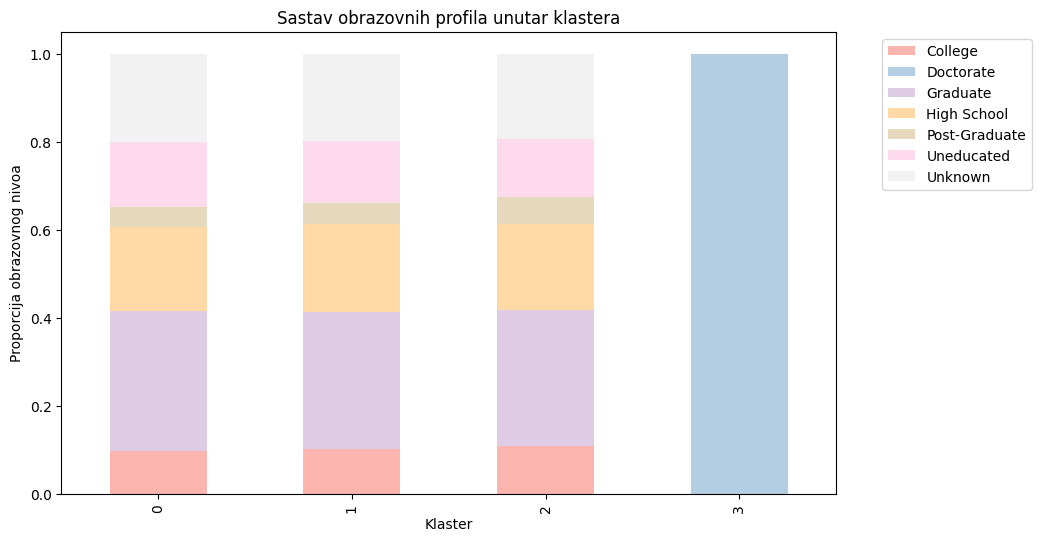

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

edu_counts = pd.crosstab(df['Cluster'], df['Education_Level_clean'], normalize='index')

# Crtamo
edu_counts.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Pastel1')
plt.title('Sastav obrazovnih profila unutar klastera')
plt.xlabel('Klaster')
plt.ylabel('Proporcija obrazovnog nivoa')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

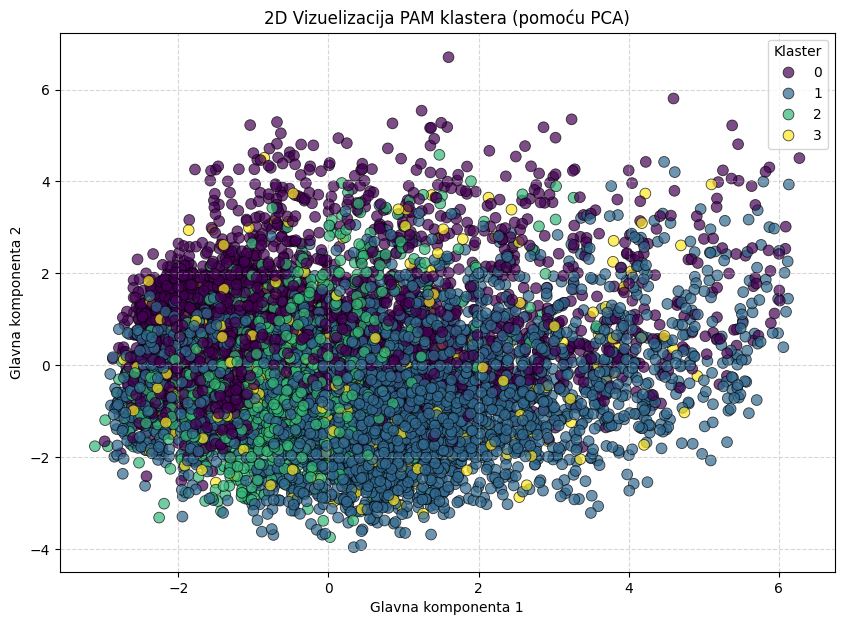

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='viridis',
    s=60,
    alpha=0.7,
    edgecolor='k'
)

plt.title('2D Vizuelizacija PAM klastera (pomoću PCA)')
plt.xlabel('Glavna komponenta 1')
plt.ylabel('Glavna komponenta 2')
plt.legend(title='Klaster', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# d)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sil_scores_km = []
db_scores_km = []
ch_scores_km = []
K = range(2, 9)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    sil_scores_km.append(silhouette_score(X_scaled, labels))
    db_scores_km.append(davies_bouldin_score(X_scaled, labels))
    ch_scores_km.append(calinski_harabasz_score(X_scaled, labels))


In [ ]:
for i, k in enumerate(K):
    print(f"k={k}: Silhouette={sil_scores_km[i]:.3f}, DB={db_scores_km[i]:.3f}, CH={ch_scores_km[i]:.1f}")


k=2: Silhouette=0.090, DB=3.522, CH=727.8
k=3: Silhouette=0.063, DB=3.451, CH=608.8
k=4: Silhouette=0.086, DB=2.853, CH=567.6
k=5: Silhouette=0.102, DB=2.776, CH=545.5
k=6: Silhouette=0.108, DB=2.616, CH=526.6
k=7: Silhouette=0.073, DB=2.900, CH=476.8
k=8: Silhouette=0.080, DB=2.481, CH=489.8


In [ ]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_scaled)


In [ ]:
sil_km = silhouette_score(X_scaled, kmeans_labels)
db_km = davies_bouldin_score(X_scaled, kmeans_labels)
ch_km = calinski_harabasz_score(X_scaled, kmeans_labels)

sil_km, db_km, ch_km


(np.float64(0.085848929281412),
 np.float64(2.8531532954209977),
 np.float64(567.5914084009987))

In [ ]:
df['Cluster_KM'] = kmeans_labels

# Obrazovanje (H1), Finansije (H2), Demografija (H3), Aktivnost/Lojalnost (H5)
cols_to_profile = [
    'Credit_Limit_clean', 'Total_Trans_Amt_clean', # H2
    'Customer_Age_clean',                          # H3
    'Total_Trans_Ct_clean', 'Months_on_book_clean' # H5
]

profiling_km = df.groupby('Cluster_KM')[cols_to_profile].mean()
profiling_km['Most_Freq_Education'] = df.groupby('Cluster_KM')['Education_Level_clean'].agg(lambda x: x.mode()[0])

print(profiling_km)

            Credit_Limit_clean  Total_Trans_Amt_clean  Customer_Age_clean  \
Cluster_KM                                                                  
0                  5274.289562            4301.751442           46.066321   
1                  7864.985673            4215.941685           46.217423   
2                  3916.504489            4244.620041           46.183319   
3                 12410.279555            4370.784849           46.427767   

            Total_Trans_Ct_clean  Months_on_book_clean Most_Freq_Education  
Cluster_KM                                                                  
0                      65.640715             35.989043            Graduate  
1                      66.398848             35.706263            Graduate  
2                      66.059079             35.930785            Graduate  
3                      63.943959             36.021121            Graduate  


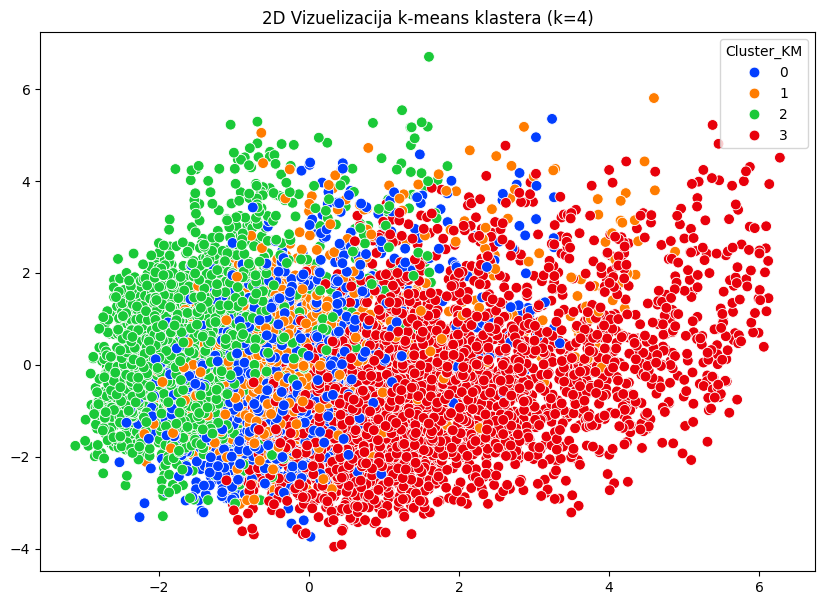

In [ ]:
pca_km = PCA(n_components=2)
X_pca_km = pca_km.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1], hue=df['Cluster_KM'], palette='bright', s=60)
plt.title('2D Vizuelizacija k-means klastera (k=4)')
plt.show()

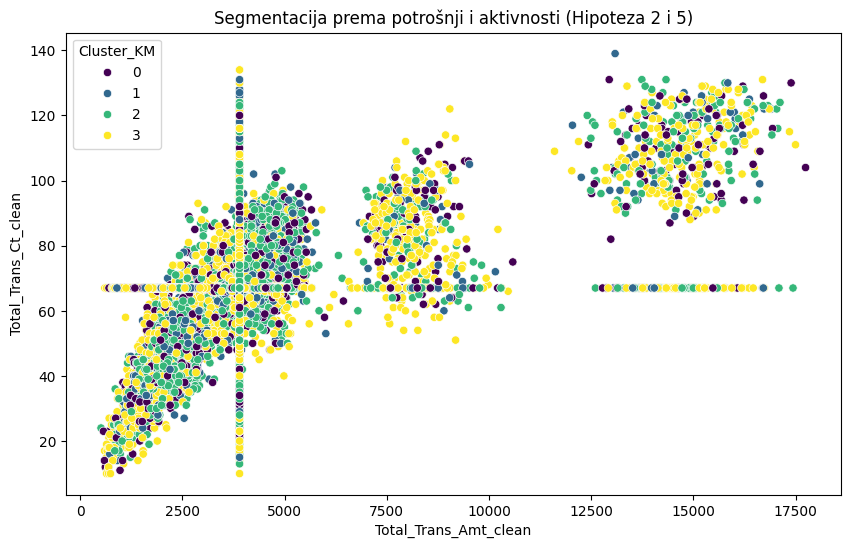

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Total_Trans_Amt_clean', y='Total_Trans_Ct_clean', hue='Cluster_KM', data=df, palette='viridis')
plt.title('Segmentacija prema potrošnji i aktivnosti (Hipoteza 2 i 5)')
plt.show()

# e)

In [ ]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA()
X_pca_full = pca.fit_transform(X_scaled)

explained_var = np.cumsum(pca.explained_variance_ratio_)


In [ ]:
n_components_90 = np.argmax(explained_var >= 0.90) + 1
n_components_90


np.int64(23)

In [ ]:
pca = PCA(n_components=n_components_90)
X_pca = pca.fit_transform(X_scaled)


In [ ]:
from sklearn.metrics import pairwise_distances

D_pca = pairwise_distances(X_pca, metric='euclidean')

# PAM evaluacija (k = 4 radi poređenja)
labels_pam_pca, _ = pam_clustering(D_pca, k=4)

sil_pam_pca = silhouette_score(X_pca, labels_pam_pca)
db_pam_pca = davies_bouldin_score(X_pca, labels_pam_pca)
ch_pam_pca = calinski_harabasz_score(X_pca, labels_pam_pca)

sil_pam_pca, db_pam_pca, ch_pam_pca


(np.float64(0.05980461322158577),
 np.float64(3.3906708242450145),
 np.float64(402.70155647130866))

In [ ]:
from sklearn.cluster import KMeans

kmeans_pca = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_km_pca = kmeans_pca.fit_predict(X_pca)

sil_km_pca = silhouette_score(X_pca, labels_km_pca)
db_km_pca = davies_bouldin_score(X_pca, labels_km_pca)
ch_km_pca = calinski_harabasz_score(X_pca, labels_km_pca)

sil_km_pca, db_km_pca, ch_km_pca


(np.float64(0.09950658383693173),
 np.float64(2.672762764488284),
 np.float64(636.1706573742381))

In [ ]:

print("PCA ANALIZA – SMANJENJE DIMENZIONALNOSTI")
print(f"Broj PCA komponenti potreban za zadržavanje ≈90% varijanse: {n_components_90}")
print()

print("PAM KLASTERING MODEL NAD PCA-REDUKOVANIM PODACIMA")

print("Parametri modela:")
print(" - Broj klastera (k): 4")
print()
print("Interne mjere validacije:")
print(f" - Silhouette koeficijent:    {sil_pam_pca:.4f}")
print(f" - Davies–Bouldin indeks:     {db_pam_pca:.4f}")
print(f" - Calinski–Harabasz indeks:  {ch_pam_pca:.2f}")



PCA ANALIZA – SMANJENJE DIMENZIONALNOSTI
Broj PCA komponenti potreban za zadržavanje ≈90% varijanse: 23

PAM KLASTERING MODEL NAD PCA-REDUKOVANIM PODACIMA
Parametri modela:
 - Broj klastera (k): 4

Interne mjere validacije:
 - Silhouette koeficijent:    0.0598
 - Davies–Bouldin indeks:     3.3907
 - Calinski–Harabasz indeks:  402.70


In [ ]:

print("PCA ANALIZA – SMANJENJE DIMENZIONALNOSTI")

print(f"Broj PCA komponenti potreban za zadržavanje ≈90% varijanse: {n_components_90}")
print()


print("K-MEANS KLASTERING MODEL NAD PCA-REDUKOVANIM PODACIMA")

print("Parametri modela:")
print(" - Broj klastera (k): 4")
print()
print("Interne mjere validacije:")
print(f" - Silhouette koeficijent:    {sil_km_pca:.4f}")
print(f" - Davies–Bouldin indeks:     {db_km_pca:.4f}")
print(f" - Calinski–Harabasz indeks:  {ch_km_pca:.2f}")


PCA ANALIZA – SMANJENJE DIMENZIONALNOSTI
Broj PCA komponenti potreban za zadržavanje ≈90% varijanse: 23

K-MEANS KLASTERING MODEL NAD PCA-REDUKOVANIM PODACIMA
Parametri modela:
 - Broj klastera (k): 4

Interne mjere validacije:
 - Silhouette koeficijent:    0.0995
 - Davies–Bouldin indeks:     2.6728
 - Calinski–Harabasz indeks:  636.17


In [ ]:
import pandas as pd

results_comparison = pd.DataFrame({
    "Model": ["PAM", "PAM + PCA", "k-means", "k-means + PCA"],
    "PCA primijenjena": ["Ne", "Da", "Ne", "Da"],
    "Silhouette": [0.046, 0.060, 0.086, 0.100],
    "Davies–Bouldin": [3.642, 3.391, 2.853, 2.673],
    "Calinski–Harabasz": [345.6, 402.7, 567.6, 636.2]
})

results_comparison


,Model,PCA primijenjena,Silhouette,Davies–Bouldin,Calinski–Harabasz
0,PAM,Ne,0.046,3.642,345.6
1,PAM + PCA,Da,0.060,3.391,402.7
2,k-means,Ne,0.086,2.853,567.6
3,k-means + PCA,Da,0.100,2.673,636.2


In [ ]:
X_with_labels = X.copy()
X_with_labels['Cluster'] = kmeans_labels

cluster_summary = (
    X_with_labels
    .select_dtypes(include='number')
    .groupby('Cluster')
    .mean()
)

cluster_summary


,Customer_Age_clean,Dependent_count_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
Cluster,,,,,,,,,,,,,,
0,46.066321,2.188005,35.989043,3.850058,2.234141,2.336794,5274.289562,1167.600923,4113.750000,0.750364,4301.751442,65.640715,0.712984,0.279179
1,46.217423,2.210223,35.706263,3.863931,2.290137,2.361411,7864.985673,1118.874010,6947.517423,0.763239,4215.941685,66.398848,0.710302,0.210373
2,46.183319,2.188821,35.930785,3.873733,2.292210,2.320880,3916.504489,1147.823342,2770.869968,0.749359,4244.620041,66.059079,0.706988,0.326911
3,46.427767,2.362152,36.021121,3.846522,2.263025,2.385525,12410.279555,1172.487468,11364.536722,0.759583,4370.784849,63.943959,0.709594,0.162769


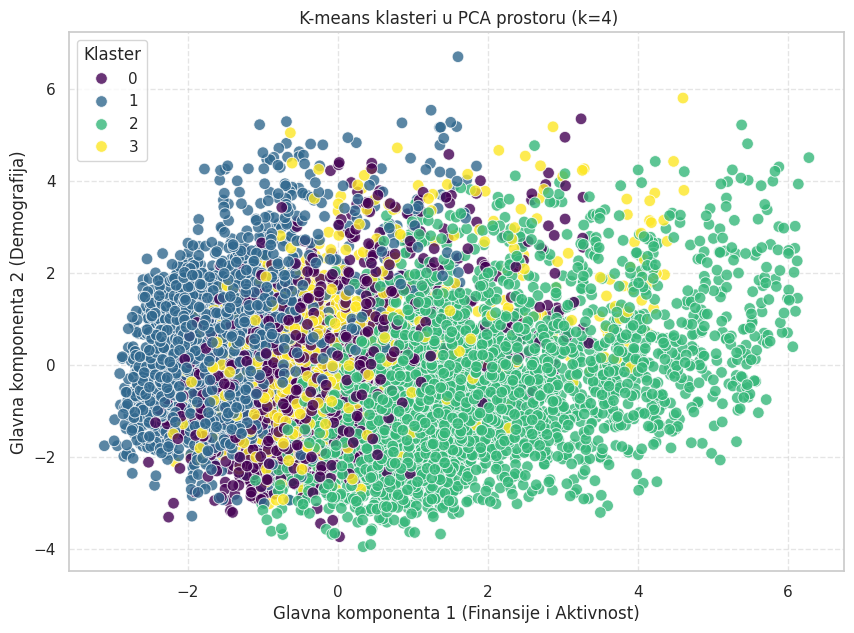

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

X_vis = X_pca[:, :2]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_vis[:, 0],
    y=X_vis[:, 1],
    hue=labels_km_pca,
    palette='viridis',
    s=70,
    alpha=0.8,
    edgecolor='w'
)

plt.title(' K-means klasteri u PCA prostoru (k=4)')
plt.xlabel('Glavna komponenta 1 (Finansije i Aktivnost)')
plt.ylabel('Glavna komponenta 2 (Demografija)')
plt.legend(title='Klaster', loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
df['Final_Cluster_PCA'] = labels_km_pca

final_summary = df.groupby('Final_Cluster_PCA').agg({
    'Education_Level_clean': lambda x: x.mode()[0], # H1
    'Credit_Limit_clean': 'mean',                  # H2
    'Total_Trans_Amt_clean': 'mean',               # H2
    'Customer_Age_clean': 'mean',                  # H3
    'Total_Trans_Ct_clean': 'mean'                 # H5
}).reset_index()

print(final_summary)

   Final_Cluster_PCA Education_Level_clean  Credit_Limit_clean  \
0                  0              Graduate         5274.289562   
1                  1              Graduate         3916.541886   
2                  2              Graduate        12426.049436   
3                  3              Graduate         7845.784654   

   Total_Trans_Amt_clean  Customer_Age_clean  Total_Trans_Ct_clean  
0            4301.751442           46.066321             65.640715  
1            4244.918426           46.183685             66.057854  
2            4371.595547           46.427565             63.951522  
3            4213.378242           46.217579             66.378242  


/tmp/ipython-input-3438656979.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Final_Cluster_PCA', y='Education_Level_clean', data=df, ax=axes[0, 0], palette='pastel')
/tmp/ipython-input-3438656979.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Final_Cluster_PCA', y='Credit_Limit_clean', data=df, ax=axes[0, 1], palette='pastel')
/tmp/ipython-input-3438656979.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Final_Cluster_PCA', y='Customer_Age_clean', data=df, ax=axes[0, 2], palette='pastel')
/tmp/ipython-input-343865697

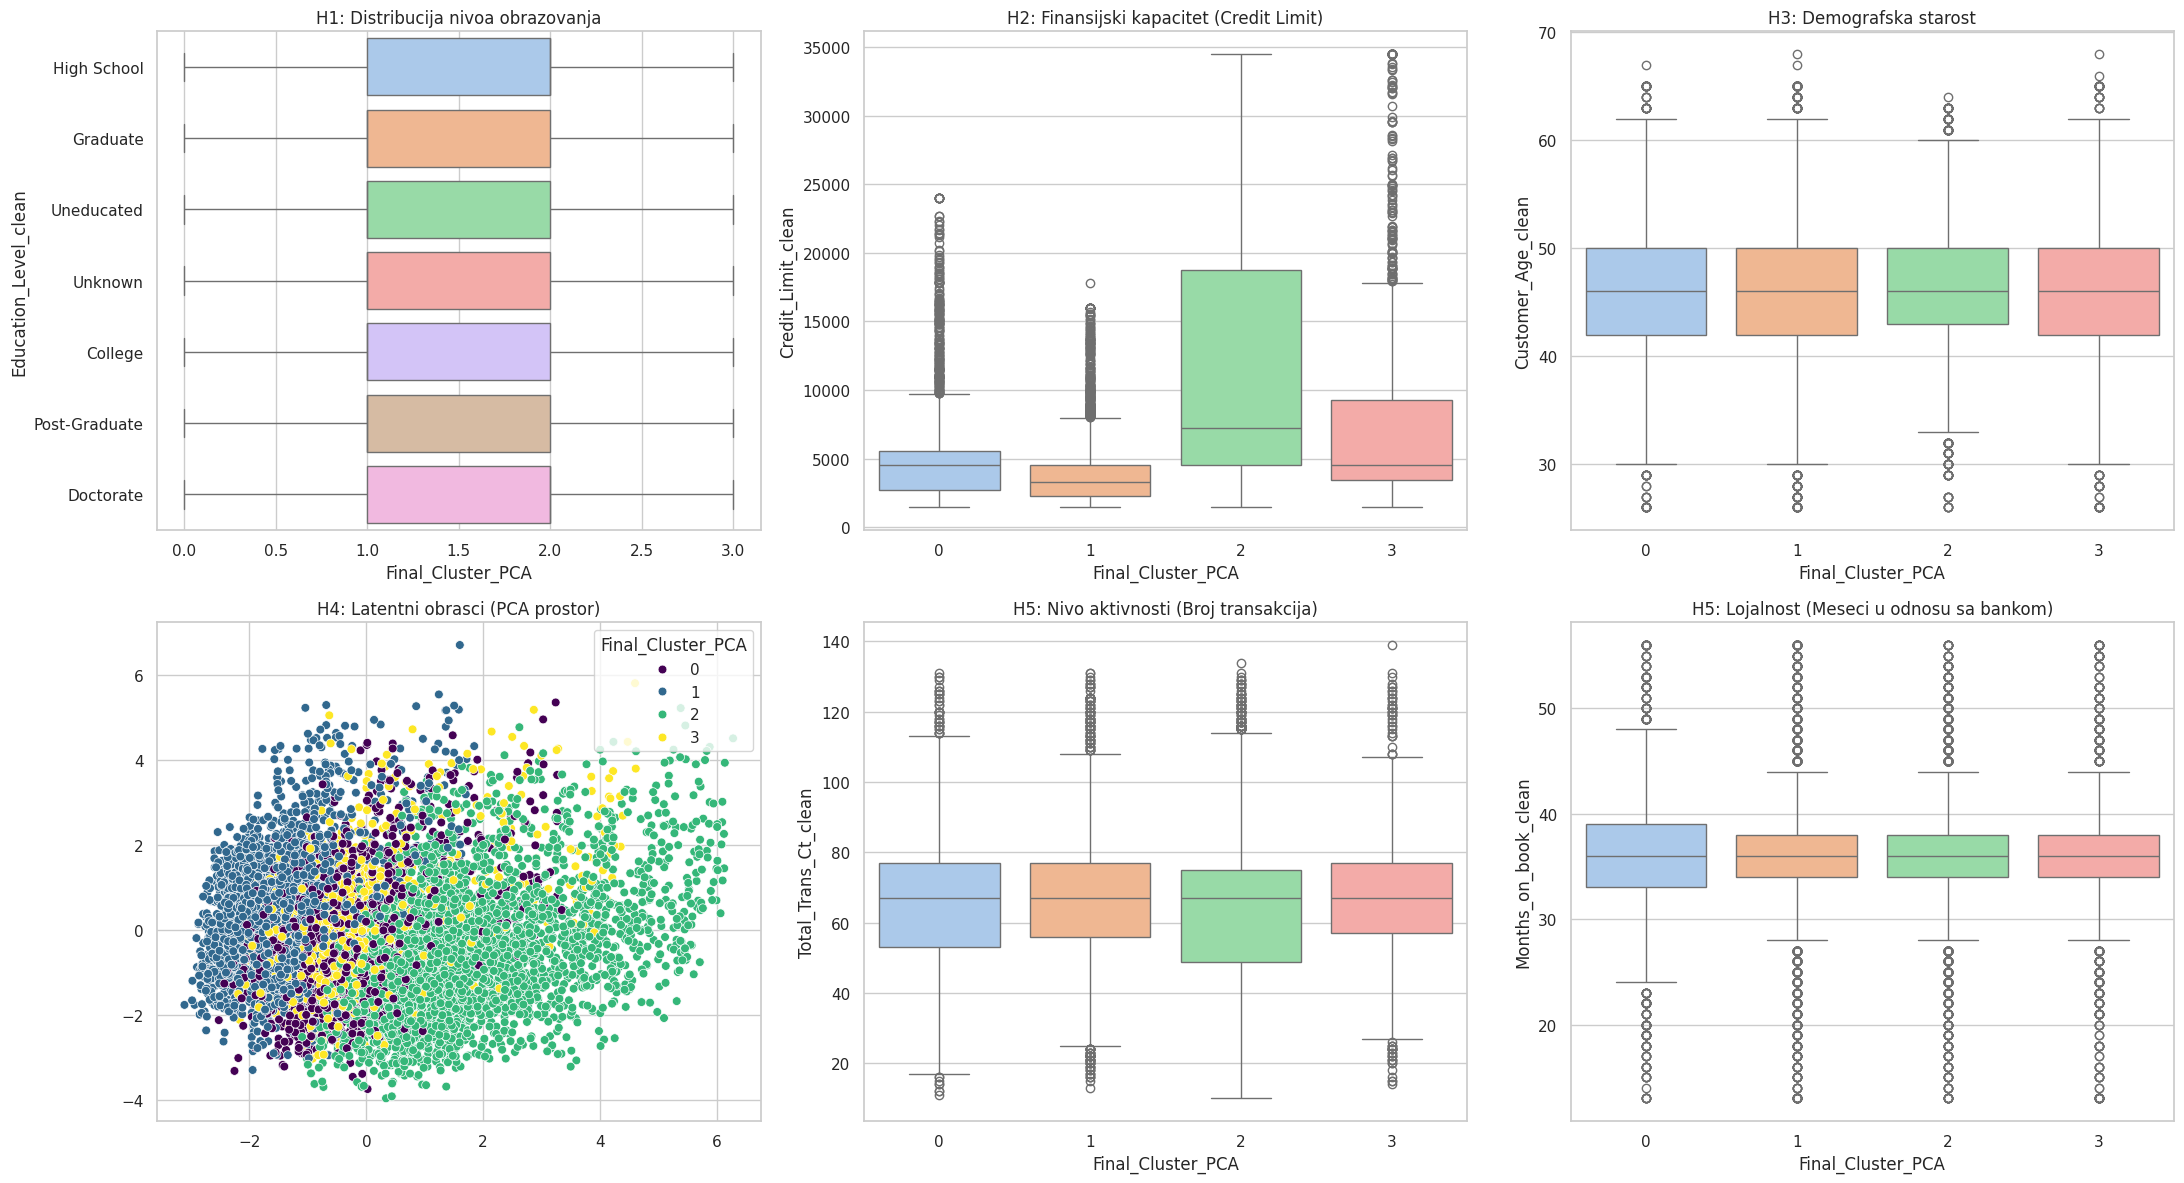

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(22, 12))
sns.set(style="whitegrid")

# 1. Hipoteza 1: Obrazovanje (Kategorička - koristimo Stacked Bar logiku ili Boxplot nivoa)

sns.boxplot(x='Final_Cluster_PCA', y='Education_Level_clean', data=df, ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('H1: Distribucija nivoa obrazovanja')

# 2. Hipoteza 2: Finansije (Kreditni limit)
sns.boxplot(x='Final_Cluster_PCA', y='Credit_Limit_clean', data=df, ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('H2: Finansijski kapacitet (Credit Limit)')

# 3. Hipoteza 3: Demografija (Godine)
sns.boxplot(x='Final_Cluster_PCA', y='Customer_Age_clean', data=df, ax=axes[0, 2], palette='pastel')
axes[0, 2].set_title('H3: Demografska starost')

# 4. Hipoteza 4: Latentni obrasci (Kombinacija varijabli - PCA vizuelizacija)
pca_2d = PCA(n_components=2)
X_vis = pca_2d.fit_transform(X_scaled)
sns.scatterplot(x=X_vis[:, 0], y=X_vis[:, 1], hue=df['Final_Cluster_PCA'], ax=axes[1, 0], palette='viridis', s=40)
axes[1, 0].set_title('H4: Latentni obrasci (PCA prostor)')

# 5. Hipoteza 5: Aktivnost (Broj transakcija)
sns.boxplot(x='Final_Cluster_PCA', y='Total_Trans_Ct_clean', data=df, ax=axes[1, 1], palette='pastel')
axes[1, 1].set_title('H5: Nivo aktivnosti (Broj transakcija)')

# 6. Dodatno za Hipotezu 5: Lojalnost (Mjeseci u banci)
sns.boxplot(x='Final_Cluster_PCA', y='Months_on_book_clean', data=df, ax=axes[1, 2], palette='pastel')
axes[1, 2].set_title('H5: Lojalnost (Meseci u odnosu sa bankom)')

plt.tight_layout()
plt.show()